# 04 - Model Evaluation & Business Impact

Answers the **risk monitoring** questions:

- How many transactions should investigators review?
- How many fraud cases does the system detect?
- How many legitimate transactions are wrongly flagged?
- What is the value of fraud caught vs missed?

### Business assumptions (edit in `src/evaluate.py`)
- Reviewing one alert costs **€5** of investigator time.
- A missed fraud costs the bank the **full transaction amount**.
- Net benefit = fraud value caught − review cost.

In [1]:
import sys
sys.path.append("..")  # so we can import from src/

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from src.plots import set_style, save, LEGIT_COLOR, FRAUD_COLOR, MUTED_COLOR
set_style()
pd.set_option("display.float_format", "{:,.4f}".format)

In [2]:
from src.evaluate import threshold_table, business_impact, outcome_labels, REVIEW_COST_EUR

test_scores = pd.read_csv("../data/test_scores.csv")
comparison = pd.read_csv("../dashboard/data/model_comparison.csv", index_col="model")

best_model = comparison["pr_auc"].idxmax()
print(f"Best model by PR-AUC: {best_model} ({comparison.loc[best_model, 'pr_auc']:.3f})")

y = test_scores["Class"]; amount = test_scores["Amount"]; score = test_scores[best_model]

Best model by PR-AUC: Random Forest (class-weighted) (0.811)


## Choosing the alert threshold

The model gives every transaction a fraud score from 0 to 1. The **threshold** decides which scores become alerts. Lower threshold = more fraud caught, but more false alerts.

In [3]:
table = threshold_table(y, score, amount)
table

,threshold,alerts,fraud_caught,fraud_missed,false_alerts,precision,recall,fraud_value_caught_eur,fraud_value_missed_eur,review_cost_eur,net_benefit_eur
0,0.0500,290,120,22,170,0.4138,0.8451,"16,019.3500","3,858.5300","1,450.0000","14,569.3500"
1,0.1000,175,116,26,59,0.6629,0.8169,"16,011.3400","3,866.5400",875.0000,"15,136.3400"
2,0.1500,148,115,27,33,0.7770,0.8099,"16,007.5800","3,870.3000",740.0000,"15,267.5800"
3,0.2000,141,114,28,27,0.8085,0.8028,"16,000.5200","3,877.3600",705.0000,"15,295.5200"
4,0.2500,138,114,28,24,0.8261,0.8028,"16,000.5200","3,877.3600",690.0000,"15,310.5200"
5,0.3000,131,111,31,20,0.8473,0.7817,"15,807.2500","4,070.6300",655.0000,"15,152.2500"
6,0.3500,125,110,32,15,0.8800,0.7746,"15,788.2100","4,089.6700",625.0000,"15,163.2100"
7,0.4000,122,109,33,13,0.8934,0.7676,"15,548.2800","4,329.6000",610.0000,"14,938.2800"
8,0.4500,121,109,33,12,0.9008,0.7676,"15,548.2800","4,329.6000",605.0000,"14,943.2800"
9,0.5000,120,109,33,11,0.9083,0.7676,"15,548.2800","4,329.6000",600.0000,"14,948.2800"


We choose the threshold with the **highest net benefit** (fraud value caught minus review cost).

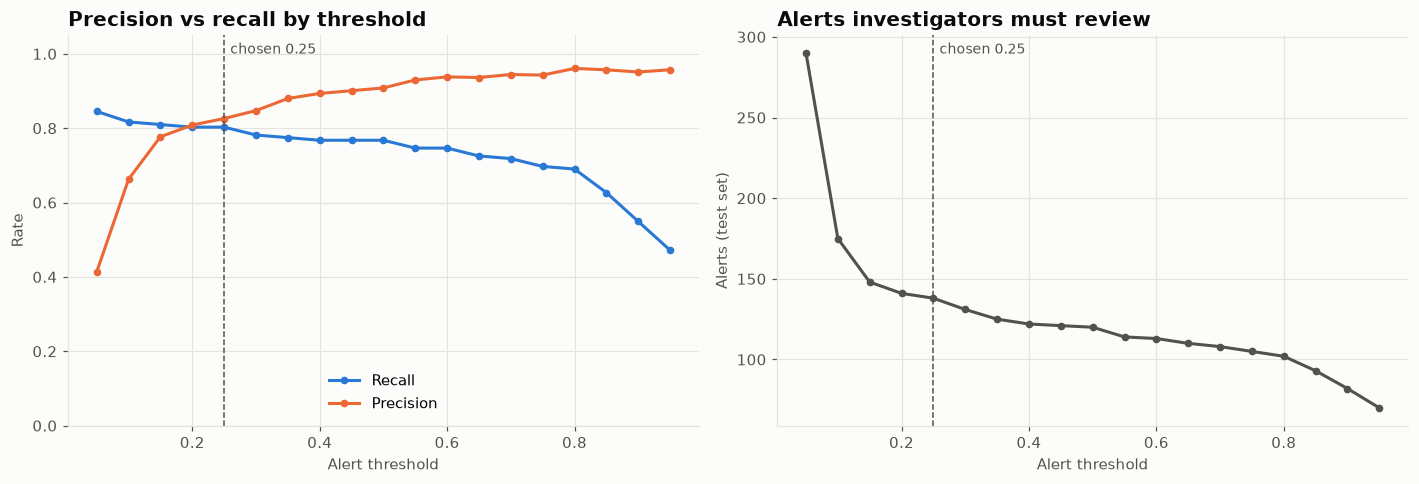

In [4]:
best_row = table.loc[table["net_benefit_eur"].idxmax()]
THRESHOLD = best_row["threshold"]

fig, axes = plt.subplots(1, 2, figsize=(13, 4.5))
axes[0].plot(table["threshold"], table["recall"], color=LEGIT_COLOR, marker="o", markersize=4, label="Recall")
axes[0].plot(table["threshold"], table["precision"], color=FRAUD_COLOR, marker="o", markersize=4, label="Precision")
axes[0].set_title("Precision vs recall by threshold")
axes[0].set_xlabel("Alert threshold"); axes[0].set_ylabel("Rate")
axes[0].set_ylim(0, 1.05); axes[0].legend(loc="lower center")

axes[1].plot(table["threshold"], table["alerts"], color=MUTED_COLOR, marker="o", markersize=4)
axes[1].set_title("Alerts investigators must review")
axes[1].set_xlabel("Alert threshold"); axes[1].set_ylabel("Alerts (test set)")
for ax in axes:
    ax.axvline(THRESHOLD, color=MUTED_COLOR, linestyle="--", linewidth=1)
    ax.annotate(f"chosen {THRESHOLD}", (THRESHOLD, 1), xycoords=("data", "axes fraction"),
                xytext=(4, -12), textcoords="offset points", fontsize=9, color=MUTED_COLOR)
fig.tight_layout()
save(fig, "06_threshold_tradeoff")
plt.show()

In [5]:
impact = business_impact(y, score, amount, THRESHOLD)
pd.Series(impact)

threshold                     0.2500
alerts                      138.0000
fraud_caught                114.0000
fraud_missed                 28.0000
false_alerts                 24.0000
precision                     0.8261
recall                        0.8028
fraud_value_caught_eur   16,000.5200
fraud_value_missed_eur    3,877.3600
review_cost_eur             690.0000
net_benefit_eur          15,310.5200
dtype: float64

## Confusion matrix at the chosen threshold

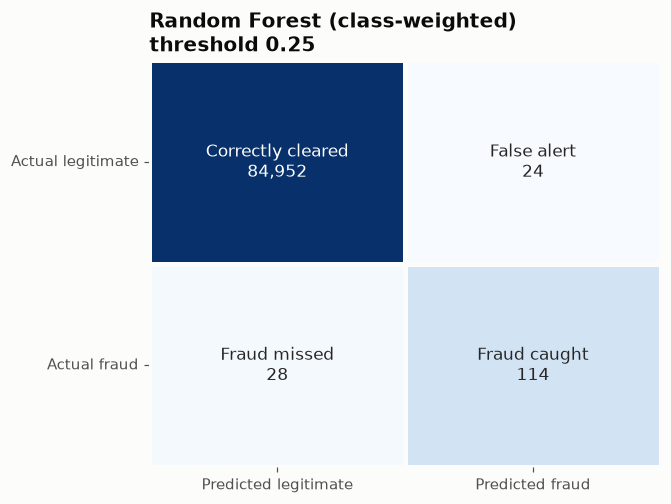

In [6]:
from sklearn.metrics import confusion_matrix
cm = confusion_matrix(y, score >= THRESHOLD)
labels = [["Correctly cleared", "False alert"], ["Fraud missed", "Fraud caught"]]
annot = [[f"{labels[i][j]}\n{cm[i, j]:,}" for j in range(2)] for i in range(2)]

fig, ax = plt.subplots(figsize=(6, 4.8))
sns.heatmap(np.log10(cm + 1), annot=annot, fmt="", cmap="Blues", cbar=False, ax=ax,
            linewidths=2, linecolor="#fcfcfb", annot_kws={"fontsize": 11})
ax.set_xticklabels(["Predicted legitimate", "Predicted fraud"])
ax.set_yticklabels(["Actual legitimate", "Actual fraud"], rotation=0)
ax.set_title(f"{best_model}\nthreshold {THRESHOLD}")
save(fig, "07_confusion_matrix")
plt.show()

## Financial view

In [7]:
money = pd.Series({
    "Fraud value in test set": amount[y == 1].sum(),
    "Fraud value caught": impact["fraud_value_caught_eur"],
    "Fraud value missed": impact["fraud_value_missed_eur"],
    "Review cost": impact["review_cost_eur"],
    "Net benefit": impact["net_benefit_eur"],
})
money.map("€{:,.2f}".format)

Fraud value in test set    €19,877.88
Fraud value caught         €16,000.52
Fraud value missed          €3,877.36
Review cost                   €690.00
Net benefit                €15,310.52
dtype: str

In [8]:
missed = test_scores[(y == 1) & (score < THRESHOLD)]
print(f"Missed frauds: {len(missed)} | median amount €{missed['Amount'].median():.2f} | largest €{missed['Amount'].max():,.2f}")
missed.sort_values("Amount", ascending=False)[["transaction_id", "Amount", best_model]].head(10)

Missed frauds: 28 | median amount €2.50 | largest €1,096.99


,transaction_id,Amount,Random Forest (class-weighted)
53321,248323,"1,096.9900",0.0050
64664,194677,723.2100,0.0199
66251,100243,549.0600,0.0049
990,67806,519.9000,0.0000
65143,145247,451.2700,0.0348
55220,101129,320.0000,0.0000
44560,52290,105.9900,0.0000
16309,112393,45.0300,0.0050
35781,119246,29.9500,0.0050
829,231119,8.0000,0.0099


## Export for Tableau

In [9]:
preds = test_scores[["transaction_id", "Amount", "Class"]].rename(columns={"Amount": "amount", "Class": "is_fraud"})
preds["fraud_score"] = score.round(4)
preds["flagged"] = (score >= THRESHOLD).astype(int)
preds["outcome"] = outcome_labels(y, score, THRESHOLD)
preds.to_csv("../dashboard/data/model_predictions.csv", index=False)

table.assign(model=best_model).to_csv("../dashboard/data/threshold_tradeoff.csv", index=False)
pd.DataFrame([{**impact, "model": best_model, "review_cost_per_alert_eur": REVIEW_COST_EUR}]).to_csv(
    "../dashboard/data/model_kpis.csv", index=False)
print("Saved model_predictions.csv, threshold_tradeoff.csv, model_kpis.csv to dashboard/data/")

Saved model_predictions.csv, threshold_tradeoff.csv, model_kpis.csv to dashboard/data/
